# Dar_004 — P1 dated and subsurface thermal context
**Datasets:** D20 Diviner RDR (two ten-minute 2013 products), D28 Apollo 15 heat-flow
tables plus the publisher's sensor/depth export, D38 south-polar 0.5-degree cumulative
Diviner temperatures. Complements Dar_001/002; does not replace their seven-region PCP EDA.

**Questions:** Which channels/quality states and locations do the dated RDR pilots support?
How do Apollo temperatures vary with time/depth and quality flags? Which coarse GCP
local-time/latitude bins are missing? Original notebooks 06/25 supply temperature/coverage
concepts; the readers here follow each product's own labels.

In [3]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT / "darrel stuff/EDA/shared"), str(ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"),str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Label and cohort rules
- RDR channel 1/2 `tb` is reflected radiance, **not kelvin**; only channels 3–9 enter thermal
  distributions. Report all quality flags. All-zero `qca/qge/qmi` is a strict comparison,
  with no substitution if empty; geometry-flagged diagnostics are labelled separately.
- Apollo `Time` is ms since **1970-12-31 midnight**, from its label (not Unix epoch).
  Reject bits 1/2/4/8 for the conservative clean bridge comparison; retain raw flags.
  Depth-series values use the publisher's `depth` export and cm units, not invented depths.
- GCP masks declared missing constants. Negative channel brightness values are retained
  in the raw data but counted separately; positive bolometric values alone enter physical
  temperature summaries. Local time is cyclic, not a mission chronology.

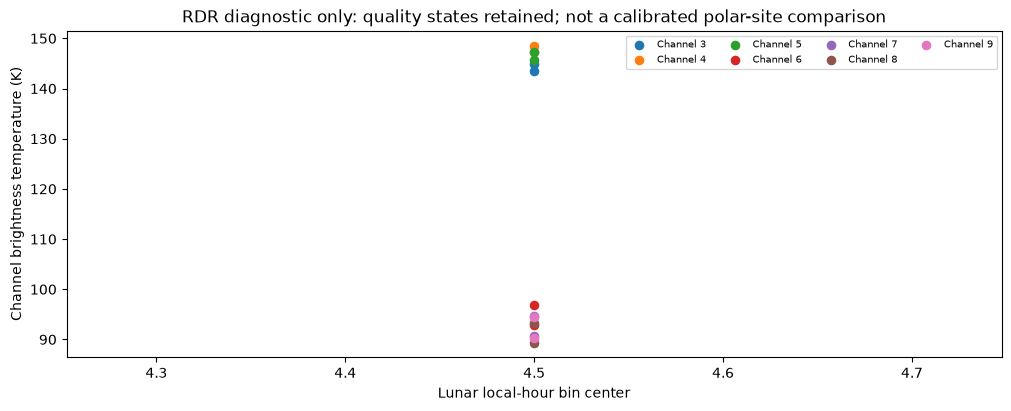

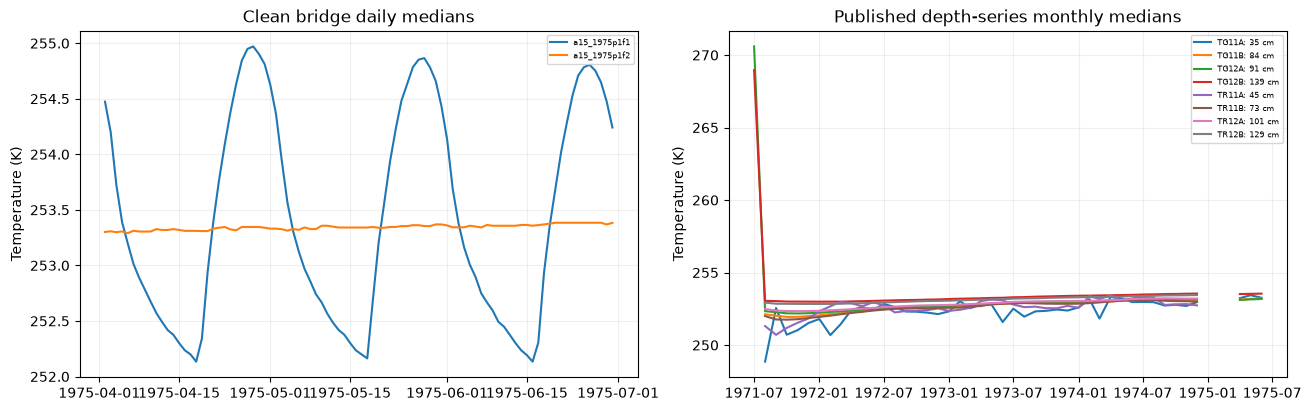

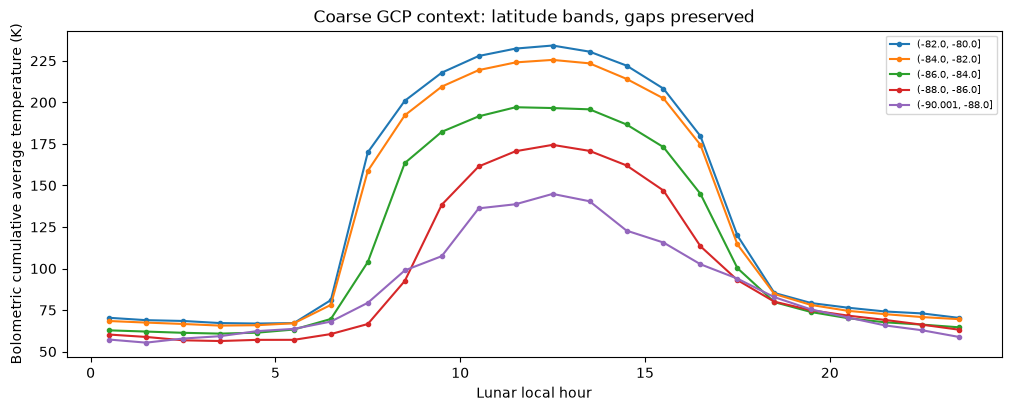

,product,rows,strict_quality_rows,lat_min,lat_max,local_hour_min,local_hour_max,timestamp_start,timestamp_end,south_polar_rows_below_80S
0,201301010000_rdr,885843,0,28.05920,57.16713,4.63389,4.76028,2013-01-01 00:00:00.111000+00:00,2013-01-01 00:09:59.932000+00:00,0
1,201301010010_rdr,885843,0,-1.63076,28.39530,4.73528,4.80639,2013-01-01 00:10:00.060000+00:00,2013-01-01 00:19:59.881000+00:00,0


,sensor,depth,count,median,min,max
0,TG11A,35,46153,252.61199,247.87997,256.91700
1,TG11B,84,46153,252.91798,251.85899,253.34300
2,TG12A,91,46405,252.99048,252.10298,283.15199
3,TG12B,139,46405,253.38349,252.91698,281.82799
4,TR11A,45,529,252.55698,250.01499,254.42000
5,TR11B,73,529,252.54699,251.70499,253.18199
6,TR12A,101,610,252.74248,252.30399,253.43598
7,TR12B,129,610,253.03748,252.79599,253.47049


**Executed findings**

{'rdr_rows': 1771686,
 'rdr_strict_quality_rows': 0,
 'rdr_south_polar_rows': 0,
 'apollo_bridge_rows': 34838,
 'apollo_clean_bridge_rows': 34819,
 'apollo_depth_rows': 187882,
 'apollo_simultaneous_gradient_rows': 176233,
 'gcp_rows': 1382400,
 'gcp_valid_tbol_rows': 1259995,
 'gcp_missing_tbol_rows': 122405,
 'scope_holds': ['RDR date/site/quality pilot is not a seven-region time history',
  'Apollo historical stations do not represent polar soils',
  'GCP averages are not extremes']}

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_004_research_thermal\20261109T150148595079Z_3c18f8


In [4]:
from moon_p1_analysis import local_time_hours
with Run(ROOT,'analysis/dar_004_research_thermal',{'datasets':['D20','D28','D38'],'scope':'downloaded bounded pilots'},'Moon/Thermal/Dar_004_research_thermal.ipynb') as run:
    run.input(Path(research_p1_readers.__file__))
    rdr=[]; coverage=[]; quality=[]
    columns=['date','utc','c','det','tb','clat','clon','cloctime','qca','qge','qmi','scalt']
    for label in pilot_files(DATA,'D20','.xml'):
        archive=label.with_suffix('.zip');pin(run,label);pin(run,archive)
        frame=read_pds4(label,archive=archive,columns=columns)
        frame['timestamp']=pd.to_datetime(frame.date+' '+frame.utc,format='%d-%b-%Y %H:%M:%S.%f',utc=True)
        frame['source_product']=label.stem
        frame['strict_quality']=frame[['qca','qge','qmi']].eq(0).all(axis=1)
        frame['is_thermal_channel']=frame.c.between(3,9)
        frame['local_hour']=local_time_hours(frame.cloctime)
        coverage.append({'product':label.stem,'rows':len(frame),'strict_quality_rows':int(frame.strict_quality.sum()),
            'lat_min':frame.clat.min(),'lat_max':frame.clat.max(),'local_hour_min':frame.local_hour.min(),
            'local_hour_max':frame.local_hour.max(),'timestamp_start':frame.timestamp.min(),'timestamp_end':frame.timestamp.max(),
            'south_polar_rows_below_80S':int(frame.clat.lt(-80).sum())})
        quality.append(frame.groupby(['source_product','qca','qge','qmi']).size().rename('rows').reset_index())
        # At most a few thermal channels per exposure; retain channel/detector identity.
        thermal=frame.loc[frame.is_thermal_channel & frame.tb.gt(0) & frame.local_hour.notna()].copy()
        thermal['local_hour_bin']=np.floor(thermal.local_hour)
        for cohort,part in [('all_quality_diagnostic',thermal),('all_flags_zero',thermal.loc[thermal.strict_quality])]:
            s=part.groupby(['source_product','c','local_hour_bin']).tb.agg(['count','median','min','max']).reset_index()
            s['cohort']=cohort;rdr.append(s)
    rdr_summary=pd.concat(rdr,ignore_index=True);rdr_coverage=pd.DataFrame(coverage)
    rdr_summary.to_csv(run.path('rdr_channel_local_time.csv'),index=False)
    rdr_coverage.to_csv(run.path('rdr_coverage.csv'),index=False)
    pd.concat(quality,ignore_index=True).to_csv(run.path('rdr_quality_states.csv'),index=False)
    fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
    for channel,part in rdr_summary.loc[rdr_summary.cohort.eq('all_quality_diagnostic')].groupby('c'):
        ax.scatter(part.local_hour_bin+.5,part['median'],label=f'Channel {channel}',s=35)
    ax.set(xlabel='Lunar local-hour bin center',ylabel='Channel brightness temperature (K)',title='RDR diagnostic only: quality states retained; not a calibrated polar-site comparison')
    ax.legend(ncol=4,fontsize=7);savefig(run,fig,'rdr_local_time_diagnostic')
    doc=DATA/'moon/eda_support/D28/bundle_documentation.md';pin(run,doc)
    bridges=[]
    for label in pilot_files(DATA,'D28','.xml'):
        pin(run,label);pin(run,label.with_suffix('.tab'))
        f=read_pds4(label);f['timestamp']=pd.Timestamp('1970-12-31',tz='UTC')+pd.to_timedelta(f.Time,unit='ms')
        if not np.equal(f['flags'],np.floor(f['flags'])).all():raise ValueError('Nonintegral Apollo flag bits')
        f['clean']=(f['flags'].astype('int64') & 15).eq(0);f['source_product']=label.stem;bridges.append(f)
    bridge=pd.concat(bridges,ignore_index=True)
    bridge.to_csv(run.path('apollo_bridge_observations.csv.gz'),index=False,compression={'method':'gzip','mtime':0,'compresslevel':3})
    bridge.groupby(['source_product','clean'])[['T','dT']].agg(['count','median','min','max']).to_csv(run.path('apollo_bridge_quality_summary.csv'))
    depth_label=DATA/'moon/eda_support/D28/a15p1_depth.xml';pin(run,depth_label);pin(run,depth_label.with_suffix('.tab'))
    depth=read_pds4(depth_label);depth['timestamp']=pd.to_datetime(depth.Time,utc=True)
    depth['clean']=(depth['flags'].astype('int64') & 15).eq(0)
    depth_summary=depth.loc[depth.clean].groupby(['sensor','depth'])['T'].agg(['count','median','min','max']).reset_index()
    depth_summary.to_csv(run.path('apollo_sensor_depth_summary.csv'),index=False)
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    for product,part in bridge.loc[bridge.clean].groupby('source_product'):
        daily=part.set_index('timestamp')[['T','dT']].resample('1D').median()
        axes[0].plot(daily.index,daily['T'],label=product)
    for (sensor,cm),part in depth.loc[depth.clean].groupby(['sensor','depth']):
        monthly=part.set_index('timestamp')['T'].resample('MS').median()
        axes[1].plot(monthly.index,monthly,label=f'{sensor}: {cm:g} cm')
    axes[0].set(title='Clean bridge daily medians',ylabel='Temperature (K)')
    axes[1].set(title='Published depth-series monthly medians',ylabel='Temperature (K)')
    for ax in axes:ax.legend(fontsize=6);ax.grid(alpha=.2)
    savefig(run,fig,'apollo_thermal_histories')
    # Pair simultaneous published temperatures; never join different timestamps as a depth profile.
    clean_depth=depth.loc[depth.clean].copy()
    if clean_depth.duplicated(['timestamp','sensor']).any():raise ValueError('Ambiguous simultaneous sensor records; no silent averaging')
    depth_wide=clean_depth.pivot(index='timestamp',columns='sensor',values='T')
    depth_wide.to_csv(run.path('apollo_simultaneous_sensor_temperatures.csv'))
    sensor_depth=clean_depth.pivot(index='timestamp',columns='sensor',values='depth')
    from itertools import combinations
    gradients=[]
    ordered=sensor_depth.median().sort_values().index
    for upper,lower in combinations(ordered,2):
        delta_m=(sensor_depth[lower]-sensor_depth[upper])/100
        mask=depth_wide[[upper,lower]].notna().all(axis=1)&delta_m.gt(0)
        gradients.append(pd.DataFrame({'timestamp':depth_wide.index[mask], 'upper_sensor':upper,'lower_sensor':lower,
            'depth_difference_m':delta_m[mask].to_numpy(),
            'observed_gradient_K_per_m':((depth_wide[lower]-depth_wide[upper])/delta_m)[mask].to_numpy()}))
    if not gradients:raise ValueError('No documented unequal-depth sensor pair available')
    gradients=pd.concat(gradients,ignore_index=True)
    gradients.to_csv(run.path('apollo_simultaneous_depth_gradients.csv'),index=False)
    gcp=[];gcp_coverage=[]
    for label in pilot_files(DATA,'D38','.xml'):
        pin(run,label);pin(run,label.with_suffix('.tab'))
        for chunk in pds4_chunks(label):
            chunk['local_hour']=local_time_hours(chunk.Local_Time)
            chunk['latitude_band']=pd.cut(chunk.Center_Latitude,[-90,-88,-86,-84,-82,-80],include_lowest=True).astype(str)
            gcp.append(chunk)
    global_polar=pd.concat(gcp,ignore_index=True)
    pd.DataFrame([{'channel':col,'finite_rows':int(global_polar[col].notna().sum()),
        'nonpositive_finite_rows':int(global_polar[col].le(0).sum()),'missing_rows':int(global_polar[col].isna().sum())}
        for col in ['t3','t4','t5','t6','t7','t8','t9','tbol']]).to_csv(run.path('gcp_channel_coverage.csv'),index=False)
    global_polar['valid_tbol']=global_polar.tbol.gt(0)&global_polar.local_hour.notna()
    global_polar['local_hour_bin']=np.floor(global_polar.local_hour)
    gcp_summary=global_polar.loc[global_polar.valid_tbol].groupby(['latitude_band','local_hour_bin']).tbol.agg(['count','median',lambda v:v.quantile(.1),lambda v:v.quantile(.9)]).reset_index()
    gcp_summary.columns=['latitude_band','local_hour_bin','rows','median_K','q10_K','q90_K']
    gcp_summary.to_csv(run.path('gcp_latitude_local_time.csv'),index=False)
    global_polar.groupby(['latitude_band','local_hour_bin'],dropna=False).valid_tbol.agg(['size','sum']).to_csv(run.path('gcp_bin_coverage.csv'))
    fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
    for band,part in gcp_summary.groupby('latitude_band'):
        full=part.set_index('local_hour_bin').reindex(range(24));ax.plot(full.index+.5,full.median_K,marker='.',label=band)
    ax.set(xlabel='Lunar local hour',ylabel='Bolometric cumulative average temperature (K)',title='Coarse GCP context: latitude bands, gaps preserved')
    ax.legend(fontsize=7);savefig(run,fig,'gcp_local_time')
    findings={'rdr_rows':int(rdr_coverage.rows.sum()),'rdr_strict_quality_rows':int(rdr_coverage.strict_quality_rows.sum()),
        'rdr_south_polar_rows':int(rdr_coverage.south_polar_rows_below_80S.sum()),'apollo_bridge_rows':len(bridge),
        'apollo_clean_bridge_rows':int(bridge.clean.sum()),'apollo_depth_rows':len(depth),'apollo_simultaneous_gradient_rows':len(gradients),'gcp_rows':len(global_polar),
        'gcp_valid_tbol_rows':int(global_polar.valid_tbol.sum()),'gcp_missing_tbol_rows':int(global_polar.tbol.isna().sum()),
        'scope_holds':['RDR date/site/quality pilot is not a seven-region time history','Apollo historical stations do not represent polar soils','GCP averages are not extremes']}
    display(rdr_coverage);display(depth_summary);save_findings(run,findings)
OUT=run.directory;print('Completed:',OUT)

## Stage 3 use and remaining work
Use coverage/quality outputs to choose a defensible dated thermal subset and to distinguish
surface versus subsurface evidence. No equipment temperatures, mission extremes or polar
gradients are inferred from Apollo. D21 ChaSTE remains registration-gated and is listed in
Dar_011; Apollo is not a replacement. RDR polar-site and all-zero-quality comparisons may
be unsupported by these particular two products; that is a result, not permission to
relax quality flags. More selected observations are needed for site/date trends.